In [58]:
import numpy as np
from tokenizers import Tokenizer
from collections import OrderedDict
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1

In [59]:
dataset = load_dataset("cardiffnlp/tweet_eval", "stance_climate")

In [60]:
# feature representation

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vector = np.zeros(len(self))
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

In [61]:
#tokenizer
vocab_size = 1000
min_frequency = 2
corpus = [text for text in dataset["train"]["text"]]
tokenizer = Project1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
token_indicator_encoder = TokenIndicator(tokenizer)

In [62]:
# cross-validation
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [63]:
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

In [64]:
# classifiers
logistic_model = Project1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)



/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [65]:
outcome_space_abortion = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_atheism = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_climate = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_feminist = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_hillary = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])

In [66]:
classifiers = OrderedDict()

In [67]:
token_indicator_encoder = TokenIndicator(tokenizer)

In [68]:
classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    classifiers['logistic_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [69]:
bow_encoder = BagOfWords(tokenizer)

classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    classifiers['logistic_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={'max_iter': 100}
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [70]:
classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    classifiers['mlp_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-4, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.072 seconds
Dataloader done! Time taken: 0.006 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1321 | train acc: 0.1620 | val loss: 1.1211 | val acc: 0.1972
Epoch 02 | train loss: 1.1138 | train acc: 0.2993 | val loss: 1.1125 | val acc: 0.2676
Epoch 03 | train loss: 1.0959 | train acc: 0.3803 | val loss: 1.1043 | val acc: 0.2958
Epoch 04 | train loss: 1.0815 | train acc: 0.4120 | val loss: 1.0964 | val acc: 0.2958


/home/richard/Documents/NLP1/Projects/NLP1/Project1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/home/richard/Documents/NLP1/Projects/NLP1/Project1/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 05 | train loss: 1.0662 | train acc: 0.5070 | val loss: 1.0889 | val acc: 0.3521
Epoch 06 | train loss: 1.0555 | train acc: 0.5704 | val loss: 1.0816 | val acc: 0.3521
Epoch 07 | train loss: 1.0390 | train acc: 0.5951 | val loss: 1.0747 | val acc: 0.3662
Epoch 08 | train loss: 1.0227 | train acc: 0.6444 | val loss: 1.0681 | val acc: 0.4085
Epoch 09 | train loss: 1.0101 | train acc: 0.6549 | val loss: 1.0617 | val acc: 0.4085
Epoch 10 | train loss: 0.9924 | train acc: 0.7113 | val loss: 1.0556 | val acc: 0.4085
Training done! Time taken: 1.232 seconds
Transforming documents...
Document transformation done! Time taken: 0.082 seconds
Dataloader done! Time taken: 0.002 seconds
Training...


... (4 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1148 | train acc: 0.3380 | val loss: 1.1206 | val acc: 0.3521
Epoch 02 | train loss: 1.0979 | train acc: 0.4331 | val loss: 1.1060 | val acc: 0.4648
Epoch 03 | train loss: 1.0821 | train acc: 0.4859 | val loss: 1.0921 | val acc: 0.4930
Epoch 04 | train loss: 1.0647 | train acc: 0.5106 | val loss: 1.0790 | val acc: 0.5070
Epoch 05 | train loss: 1.0487 | train acc: 0.5317 | val loss: 1.0666 | val acc: 0.5352
Epoch 06 | train loss: 1.0329 | train acc: 0.5387 | val loss: 1.0547 | val acc: 0.5352
Epoch 07 | train loss: 1.0202 | train acc: 0.5387 | val loss: 1.0432 | val acc: 0.5352
Epoch 08 | train loss: 1.0076 | train acc: 0.5528 | val loss: 1.0320 | val acc: 0.5352
Epoch 09 | train loss: 0.9940 | train acc: 0.5599 | val loss: 1.0214 | val acc: 0.5352
Epoch 10 | train loss: 0.9789 | train acc: 0.5634 | val loss: 1.0110 | val acc: 0.5352
Training done! Time taken: 0.233 seconds
Transforming documents...
Document transformation done! Time taken: 0.064 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0954 | train acc: 0.3979 | val loss: 1.0752 | val acc: 0.4789
Epoch 02 | train loss: 1.0790 | train acc: 0.4366 | val loss: 1.0631 | val acc: 0.4789
Epoch 03 | train loss: 1.0662 | train acc: 0.4754 | val loss: 1.0513 | val acc: 0.5211
Epoch 04 | train loss: 1.0512 | train acc: 0.5352 | val loss: 1.0397 | val acc: 0.5634
Epoch 05 | train loss: 1.0348 | train acc: 0.5563 | val loss: 1.0284 | val acc: 0.5775
Epoch 06 | train loss: 1.0221 | train acc: 0.5775 | val loss: 1.0173 | val acc: 0.5775
Epoch 07 | train loss: 1.0099 | train acc: 0.6162 | val loss: 1.0064 | val acc: 0.5493
Epoch 08 | train loss: 0.9956 | train acc: 0.6514 | val loss: 0.9960 | val acc: 0.5634
Epoch 09 | train loss: 0.9823 | train acc: 0.6972 | val loss: 0.9857 | val acc: 0.5775
Epoch 10 | train loss: 0.9700 | train acc: 0.7007 | val loss: 0.9756 | val acc: 0.5634
Training done! Time taken: 0.246 seconds


In [71]:
classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    classifiers['mlp_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-4, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.064 seconds
Dataloader done! Time taken: 0.003 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1396 | train acc: 0.2606 | val loss: 1.1183 | val acc: 0.2676
Epoch 02 | train loss: 1.1164 | train acc: 0.3169 | val loss: 1.1074 | val acc: 0.3803
Epoch 03 | train loss: 1.0908 | train acc: 0.4120 | val loss: 1.0971 | val acc: 0.3944
Epoch 04 | train loss: 1.0726 | train acc: 0.4683 | val loss: 1.0873 | val acc: 0.4225
Epoch 05 | train loss: 1.0547 | train acc: 0.5563 | val loss: 1.0781 | val acc: 0.4507
Epoch 06 | train loss: 1.0426 | train acc: 0.5458 | val loss: 1.0692 | val acc: 0.4648
Epoch 07 | train loss: 1.0234 | train acc: 0.5951 | val loss: 1.0607 | val acc: 0.4930
Epoch 08 | train loss: 1.0084 | train acc: 0.6655 | val loss: 1.0526 | val acc: 0.4930
Epoch 09 | train loss: 0.9898 | train acc: 0.6901 | val loss: 1.0448 | val acc: 0.4648
Epoch 10 | train loss: 0.9734 | train acc: 0.7148 | val loss: 1.0374 | val acc: 0.4366
Training done! Time taken: 0.292 seconds
Transforming documents...
Document transformation done! Time taken: 0.064 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0812 | train acc: 0.4437 | val loss: 1.1035 | val acc: 0.4085
Epoch 02 | train loss: 1.0631 | train acc: 0.4824 | val loss: 1.0872 | val acc: 0.4225
Epoch 03 | train loss: 1.0439 | train acc: 0.5211 | val loss: 1.0718 | val acc: 0.4366
Epoch 04 | train loss: 1.0323 | train acc: 0.5282 | val loss: 1.0565 | val acc: 0.4507
Epoch 05 | train loss: 1.0136 | train acc: 0.5775 | val loss: 1.0421 | val acc: 0.4507
Epoch 06 | train loss: 0.9991 | train acc: 0.5986 | val loss: 1.0282 | val acc: 0.4648
Epoch 07 | train loss: 0.9867 | train acc: 0.6127 | val loss: 1.0145 | val acc: 0.4648
Epoch 08 | train loss: 0.9717 | train acc: 0.6373 | val loss: 1.0013 | val acc: 0.4930
Epoch 09 | train loss: 0.9631 | train acc: 0.6690 | val loss: 0.9880 | val acc: 0.4789
Epoch 10 | train loss: 0.9466 | train acc: 0.7007 | val loss: 0.9753 | val acc: 0.4507
Training done! Time taken: 0.248 seconds
Transforming documents...
Document transformation done! Time taken: 0.065 seconds
Dataloa

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0590 | train acc: 0.5246 | val loss: 1.0515 | val acc: 0.5352
Epoch 02 | train loss: 1.0474 | train acc: 0.5282 | val loss: 1.0403 | val acc: 0.5352
Epoch 03 | train loss: 1.0309 | train acc: 0.5423 | val loss: 1.0293 | val acc: 0.5352
Epoch 04 | train loss: 1.0159 | train acc: 0.5423 | val loss: 1.0190 | val acc: 0.5352
Epoch 05 | train loss: 0.9996 | train acc: 0.5387 | val loss: 1.0091 | val acc: 0.5352
Epoch 06 | train loss: 0.9907 | train acc: 0.5458 | val loss: 0.9994 | val acc: 0.5352
Epoch 07 | train loss: 0.9743 | train acc: 0.5528 | val loss: 0.9898 | val acc: 0.5352
Epoch 08 | train loss: 0.9650 | train acc: 0.5493 | val loss: 0.9805 | val acc: 0.5352
Epoch 09 | train loss: 0.9507 | train acc: 0.5563 | val loss: 0.9716 | val acc: 0.5352
Epoch 10 | train loss: 0.9354 | train acc: 0.5528 | val loss: 0.9629 | val acc: 0.5352
Training done! Time taken: 0.437 seconds
Transforming documents...
Document transformation done! Time taken: 0.071 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1092 | train acc: 0.3239 | val loss: 1.0957 | val acc: 0.3239
Epoch 02 | train loss: 1.0885 | train acc: 0.3944 | val loss: 1.0818 | val acc: 0.3662
Epoch 03 | train loss: 1.0749 | train acc: 0.4331 | val loss: 1.0687 | val acc: 0.4085
Epoch 04 | train loss: 1.0527 | train acc: 0.5211 | val loss: 1.0560 | val acc: 0.4225
Epoch 05 | train loss: 1.0403 | train acc: 0.5387 | val loss: 1.0440 | val acc: 0.5211
Epoch 06 | train loss: 1.0285 | train acc: 0.5563 | val loss: 1.0322 | val acc: 0.5352
Epoch 07 | train loss: 1.0104 | train acc: 0.6092 | val loss: 1.0205 | val acc: 0.5352
Epoch 08 | train loss: 0.9954 | train acc: 0.6303 | val loss: 1.0091 | val acc: 0.5070
Epoch 09 | train loss: 0.9789 | train acc: 0.6972 | val loss: 0.9978 | val acc: 0.5070
Epoch 10 | train loss: 0.9669 | train acc: 0.7007 | val loss: 0.9869 | val acc: 0.5634
Training done! Time taken: 0.404 seconds


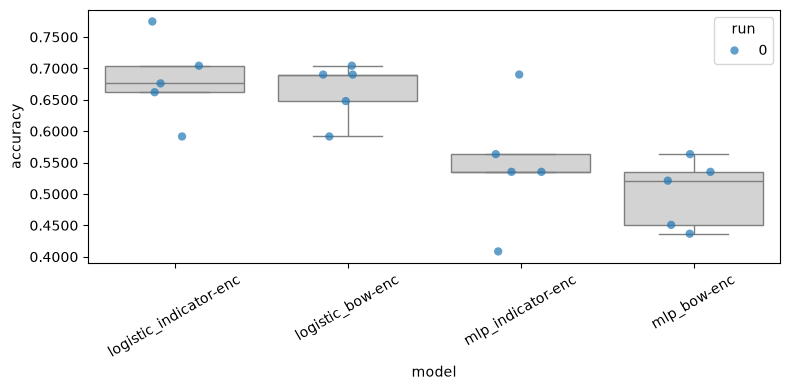

In [73]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(classifiers))